# Phase 4: Preplexity analysis

**Project:** SynText-Scanner  
**Goal:** Clean raw text data using NLP techniques (Lemmatization) and explore statistical differences between AI and Human-authored content.

In [8]:
import pandas as pd
import torch
from transformers import GPT2LMHeadModel, GPT2Tokenizer
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
print("Loading test dataset...")
df_test = pd.read_csv('../data/processed data/test_cleaned.csv')
df_test = df_test.dropna(subset=['cleaned_text', 'label']).reset_index(drop=True)

print("Initializing DistilGPT2 for Perplexity computation...")
model_id = 'distilgpt2'
tokenizer_gpt = GPT2Tokenizer.from_pretrained(model_id)
model_gpt = GPT2LMHeadModel.from_pretrained(model_id)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model_gpt.to(device)
model_gpt.eval() 
print(f"Model successfully loaded on: {device}")

def calculate_perplexity(text):
    inputs = tokenizer_gpt(text, return_tensors='pt', truncation=True, max_length=512)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model_gpt(**inputs, labels=inputs['input_ids'])
        loss = outputs.loss
        perplexity = torch.exp(loss)

    return perplexity.item()

print("\nRunning initial Zero-Shot confrontation...")
sample_human = df_test[df_test['label'] == 0]['cleaned_text'].iloc[0]
sample_ai = df_test[df_test['label'] == 1]['cleaned_text'].iloc[0]

print("Calculating...")
ppl_human = calculate_perplexity(sample_human)
ppl_ai = calculate_perplexity(sample_ai)


print(f"AI Sample Perplexity:     {ppl_ai:.2f}")
print(f"Human Sample Perplexity:  {ppl_human:.2f}")


Loading test dataset...
Initializing DistilGPT2 for Perplexity computation...


Loading weights: 100%|██████████| 76/76 [00:00<00:00, 9440.76it/s]
`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Model successfully loaded on: cuda

Running initial Zero-Shot confrontation...
Calculating...
AI Sample Perplexity:     8128.24
Human Sample Perplexity:  7873.27


In [4]:
print("Checking available columns in our dataset...")
print(f"Columns: {df_test.columns.tolist()}")
original_text_column = 'text'

try:
    print("\nRunning Zero-Shot Detection on RAW, uncleaned text...")
    sample_human_raw = df_test[df_test['label'] == 0][original_text_column].iloc[0]
    sample_ai_raw = df_test[df_test['label'] == 1][original_text_column].iloc[0]

    ppl_human_raw = calculate_perplexity(sample_human_raw)
    ppl_ai_raw = calculate_perplexity(sample_ai_raw)

    print(f"AI Sample PPL (Raw):     {ppl_ai_raw:.2f}")
    print(f"Human Sample PPL (Raw):  {ppl_human_raw:.2f}")

except KeyError:
    print(f"ERROR: The column '{original_text_column}' was not found.")
    print("We need the original text with punctuation and stop words for GPT-2.")
    print("Please check the column list above and update 'original_text_column'.")

Checking available columns in our dataset...
Columns: ['text', 'content_type', 'word_count', 'character_count', 'sentence_count', 'lexical_diversity', 'avg_sentence_length', 'avg_word_length', 'punctuation_ratio', 'flesch_reading_ease', 'gunning_fog_index', 'grammar_errors', 'passive_voice_ratio', 'predictability_score', 'burstiness', 'sentiment_score', 'label', 'cleaned_text']

Running Zero-Shot Detection on RAW, uncleaned text...
AI Sample PPL (Raw):     1829.76
Human Sample PPL (Raw):  2329.25


Preparing for batch Perplexity calculation...
Calculating PPL for 300 samples (this will take ~10-20 seconds on your RTX 5080)...


C:\Users\kevin\AppData\Local\Temp\ipykernel_36876\1062485220.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sample = df_test.groupby('label').apply(lambda x: x.sample(n=150, random_state=42)).reset_index(drop=True)


Processed 50/300 samples...
Processed 100/300 samples...
Processed 150/300 samples...
Processed 200/300 samples...
Processed 250/300 samples...
Processed 300/300 samples...

Generating final distribution plot...


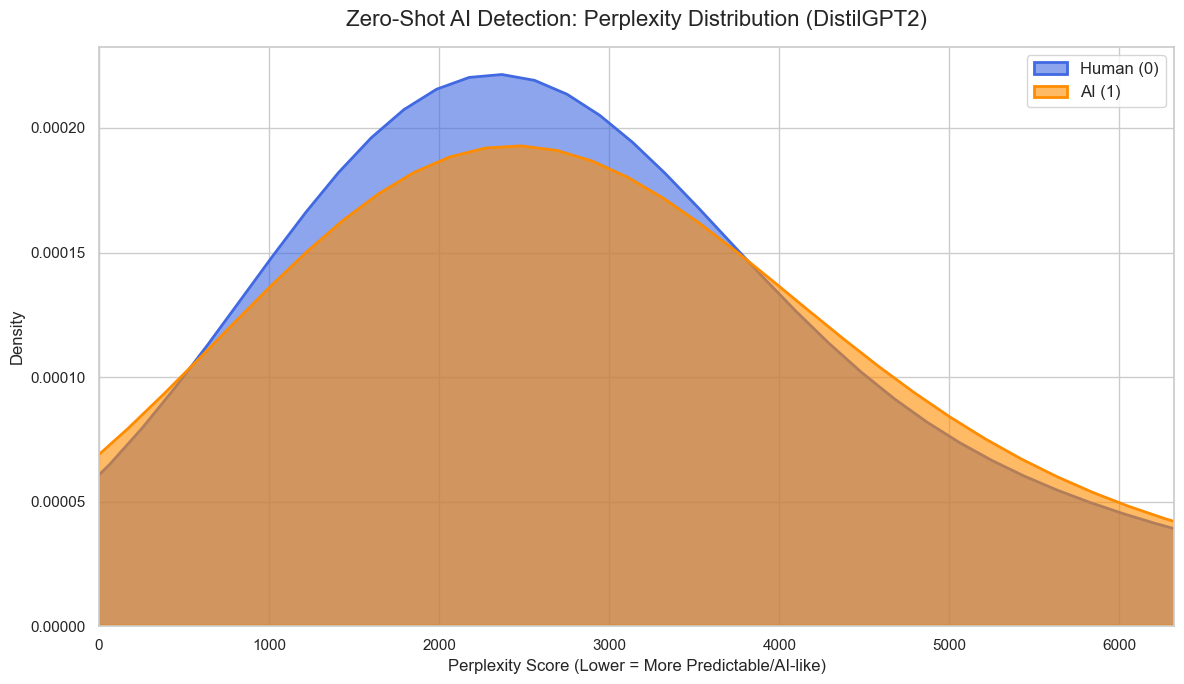

Execution complete! Analyze the distribution overlap.


In [9]:
print("Preparing for batch Perplexity calculation...")
df_sample = df_test.groupby('label').apply(lambda x: x.sample(n=150, random_state=42)).reset_index(drop=True)

print(f"Calculating PPL for {len(df_sample)} samples (this will take ~10-20 seconds on your RTX 5080)...")
ppl_results = []

for idx, text in enumerate(df_sample['text']):
    ppl = calculate_perplexity(text)
    ppl_results.append(ppl)
    if (idx + 1) % 50 == 0:
        print(f"Processed {idx + 1}/{len(df_sample)} samples...")
        
df_sample['perplexity'] = ppl_results

print("\nGenerating final distribution plot...")
plt.figure(figsize=(12, 7))

sns.set_theme(style="whitegrid")
sns.kdeplot(data=df_sample[df_sample['label'] == 0], x='perplexity', label='Human (0)', fill=True, color='royalblue', alpha=0.6, linewidth=2)
sns.kdeplot(data=df_sample[df_sample['label'] == 1], x='perplexity', label='AI (1)', fill=True, color='darkorange', alpha=0.6, linewidth=2)

plt.title('Zero-Shot AI Detection: Perplexity Distribution (DistilGPT2)', fontsize=16, pad=15)
plt.xlabel('Perplexity Score (Lower = More Predictable/AI-like)', fontsize=12)
plt.ylabel('Density', fontsize=12)

max_x_limit = np.percentile(ppl_results, 90)
plt.xlim(0, max_x_limit)

plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

print("Execution complete! Analyze the distribution overlap.")